# 路径与生产调度 · 两作业两机器排程

QuantumBridge / 工业优化 / 中文可执行案例

**执行状态：仅本地运行；未提交夸父真机；新增云任务 0。**

面向了解 Python 的读者：完成建模、检查中间结果、运行原生电路或明确标记的经典密码步骤，并与独立基线核对。

**范围边界：** 这是四工序固定路线作业车间案例；没有实现 TSP、车辆路径、复杂时间窗、设备故障或完整生产调度系统。

## 1. 原理与计算对象

两个作业 A、B 都依次经过机器 M0、M1，每道工序时长 1。四比特分别编码 A1、B1 的开始时刻 0/1，以及 A2、B2 的开始时刻 1/2。
必须满足同作业内先后顺序，以及同一机器不得同时加工。目标是加权完工时间 $2C_A+C_B$，而非声称最小化所有工厂的 makespan。罚函数为 10 倍先后和冲突违反数。

先枚举全部 16 种排程作为可行性与最优值基线，再将代价对角展开并用原生 QAOA 采样。输出实际可行串对应的工序起止时间，并绘制经典最优排程的甘特图。

## 2. 实现步骤

1. 声明工序路线、时长、时间窗和完工权重。
2. 逐候选恢复四道工序，检查先后关系和机器冲突。
3. 计算加权完工代价与罚项，枚举最优基线。
4. 训练一层原生 QAOA，输出成本 Pauli 阶数。
5. 对采样可行解解码，比较目标差、可行率和经典甘特图。

## 3. 环境与可复现参数

依赖本仓库、NumPy、Matplotlib、Jupyter；安全案例还使用已安装的 OpenSSL / cryptography。模型和电路不调用 Qiskit 或 PennyLane。Notebook 保留真实执行输出，Python 解释器版本会在下方打印。

In [1]:
import os, sys, json
get_ipython().run_line_magic('matplotlib', 'inline')
from pathlib import Path
root = next((p for p in [Path(os.environ.get("QB_REPO_ROOT", ".")).resolve(), *Path.cwd().resolve().parents] if (p/"quantumbridge").is_dir() and (p/"scripts").is_dir()), None)
if root is None:
    raise RuntimeError("Run from the QuantumBridge checkout or set QB_REPO_ROOT.")
sys.path.insert(0, str(root)); sys.path.insert(0, str(root/"scripts"))
from IPython.display import display, HTML
from application_notebook_support import STYLE, show_json, intermediate_tables, plot_intermediate, show_measurements
from quantumbridge.applications.common import run_local_case
display(HTML(STYLE))
SHOTS, SEED = 1024, 20261023
print("Execution: LOCAL ONLY | cloud submissions: 0 | shots per circuit:", SHOTS)

print(sys.version)
from quantumbridge.finance.kernels import labels
from quantumbridge.applications.common import optimization_case

Execution: LOCAL ONLY | cloud submissions: 0 | shots per circuit: 1024
3.12.6 (v3.12.6:a4a2d2b0d85, Sep  6 2024, 16:08:03) [Clang 13.0.0 (clang-1300.0.29.30)]


## 4. 完整应用建模代码

以下是本案例实际执行的应用函数，不是伪代码。底层电路、映射、演化与采样复用仓库原生接口；优化类的共享辅助函数也位于 `quantumbridge/applications/common.py`。

In [2]:
def scheduling_case():
    candidates = []
    for bits in labels(4):
        x = list(map(int, bits))
        starts = [x[0], 1 + x[2], x[1], 1 + x[3]]
        operations = [
            {"name": name, "machine": machine, "start": start, "duration": 1}
            for name, machine, start in zip(
                ("A1", "A2", "B1", "B2"), (0, 1, 0, 1), starts
            )
        ]
        precedence = int(starts[1] < starts[0] + 1) + int(starts[3] < starts[2] + 1)
        conflicts = int(starts[0] == starts[2]) + int(starts[1] == starts[3])
        objective = 2 * (starts[1] + 1) + (starts[3] + 1)
        candidates.append(
            {
                "bitstring": bits,
                "operations": operations,
                "precedence_violations": precedence,
                "machine_conflicts": conflicts,
                "feasible": precedence + conflicts == 0,
                "weighted_completion": objective,
                "makespan": max(starts) + 1,
                "objective": objective,
                "penalized_cost": objective + 10 * (precedence + conflicts),
            }
        )
    return optimization_case(
        "routing-scheduling",
        "industry",
        "Two-job two-machine scheduling",
        {
            "jobs": ["A", "B"],
            "machine_order": [0, 1],
            "operation_duration": 1,
            "start_windows": {"first_operation": [0, 1], "second_operation": [1, 2]},
            "completion_weights": {"A": 2, "B": 1},
            "penalty": 10,
            "scope": "fixed four-operation job shop; no vehicle routing or TSP claim",
        },
        candidates,
    )


In [3]:
case = scheduling_case()
show_json(case.inputs)

## 5. 中间结果与效果

下方完整列出模型候选、优化轨迹或物理中间量。图中的 exact / classical 是经典计算基线，不冒充量子实验。图表使用英文坐标避免本机中文字体缺失，解释与表格保留中文。

bitstring,operations,precedence_violations,machine_conflicts,feasible,weighted_completion,makespan,objective,penalized_cost
0000,"[{""name"": ""A1"", ""machine"": 0, ""start"": 0, ""duration"": 1}, {""name"": ""A2"", ""machine"": 1, ""start"": 1, ""duration"": 1}, {""name"": ""B1"", ""machine"": 0, ""start"": 0, ""duration"": 1}, {""name"": ""B2"", ""machine"": 1, ""start"": 1, ""duration"": 1}]",0,2,False,6,2,6,26
0001,"[{""name"": ""A1"", ""machine"": 0, ""start"": 0, ""duration"": 1}, {""name"": ""A2"", ""machine"": 1, ""start"": 1, ""duration"": 1}, {""name"": ""B1"", ""machine"": 0, ""start"": 0, ""duration"": 1}, {""name"": ""B2"", ""machine"": 1, ""start"": 2, ""duration"": 1}]",0,1,False,7,3,7,17
0010,"[{""name"": ""A1"", ""machine"": 0, ""start"": 0, ""duration"": 1}, {""name"": ""A2"", ""machine"": 1, ""start"": 2, ""duration"": 1}, {""name"": ""B1"", ""machine"": 0, ""start"": 0, ""duration"": 1}, {""name"": ""B2"", ""machine"": 1, ""start"": 1, ""duration"": 1}]",0,1,False,8,3,8,18
0011,"[{""name"": ""A1"", ""machine"": 0, ""start"": 0, ""duration"": 1}, {""name"": ""A2"", ""machine"": 1, ""start"": 2, ""duration"": 1}, {""name"": ""B1"", ""machine"": 0, ""start"": 0, ""duration"": 1}, {""name"": ""B2"", ""machine"": 1, ""start"": 2, ""duration"": 1}]",0,2,False,9,3,9,29
0100,"[{""name"": ""A1"", ""machine"": 0, ""start"": 0, ""duration"": 1}, {""name"": ""A2"", ""machine"": 1, ""start"": 1, ""duration"": 1}, {""name"": ""B1"", ""machine"": 0, ""start"": 1, ""duration"": 1}, {""name"": ""B2"", ""machine"": 1, ""start"": 1, ""duration"": 1}]",1,1,False,6,2,6,26
0101,"[{""name"": ""A1"", ""machine"": 0, ""start"": 0, ""duration"": 1}, {""name"": ""A2"", ""machine"": 1, ""start"": 1, ""duration"": 1}, {""name"": ""B1"", ""machine"": 0, ""start"": 1, ""duration"": 1}, {""name"": ""B2"", ""machine"": 1, ""start"": 2, ""duration"": 1}]",0,0,True,7,3,7,7
0110,"[{""name"": ""A1"", ""machine"": 0, ""start"": 0, ""duration"": 1}, {""name"": ""A2"", ""machine"": 1, ""start"": 2, ""duration"": 1}, {""name"": ""B1"", ""machine"": 0, ""start"": 1, ""duration"": 1}, {""name"": ""B2"", ""machine"": 1, ""start"": 1, ""duration"": 1}]",1,0,False,8,3,8,18
0111,"[{""name"": ""A1"", ""machine"": 0, ""start"": 0, ""duration"": 1}, {""name"": ""A2"", ""machine"": 1, ""start"": 2, ""duration"": 1}, {""name"": ""B1"", ""machine"": 0, ""start"": 1, ""duration"": 1}, {""name"": ""B2"", ""machine"": 1, ""start"": 2, ""duration"": 1}]",0,1,False,9,3,9,19
1000,"[{""name"": ""A1"", ""machine"": 0, ""start"": 1, ""duration"": 1}, {""name"": ""A2"", ""machine"": 1, ""start"": 1, ""duration"": 1}, {""name"": ""B1"", ""machine"": 0, ""start"": 0, ""duration"": 1}, {""name"": ""B2"", ""machine"": 1, ""start"": 1, ""duration"": 1}]",1,1,False,6,2,6,26
1001,"[{""name"": ""A1"", ""machine"": 0, ""start"": 1, ""duration"": 1}, {""name"": ""A2"", ""machine"": 1, ""start"": 1, ""duration"": 1}, {""name"": ""B1"", ""machine"": 0, ""start"": 0, ""duration"": 1}, {""name"": ""B2"", ""machine"": 1, ""start"": 2, ""duration"": 1}]",1,0,False,7,3,7,17


improvement,expected_penalized_cost,gamma,beta
0,22.5,0,0
1,22.5,0,1.9332878
2,21.641811,0.78539816,0.96664389
3,20.579875,0.78539816,1.2083049
4,19.655745,0.78539816,2.6582707
5,18.92102,1.5707963,1.2083049
6,17.275737,1.5707963,2.6582707
7,15.598979,2.3561945,2.6582707
8,14.76259,3.1415927,2.6582707
9,14.689762,3.3415927,2.6582707


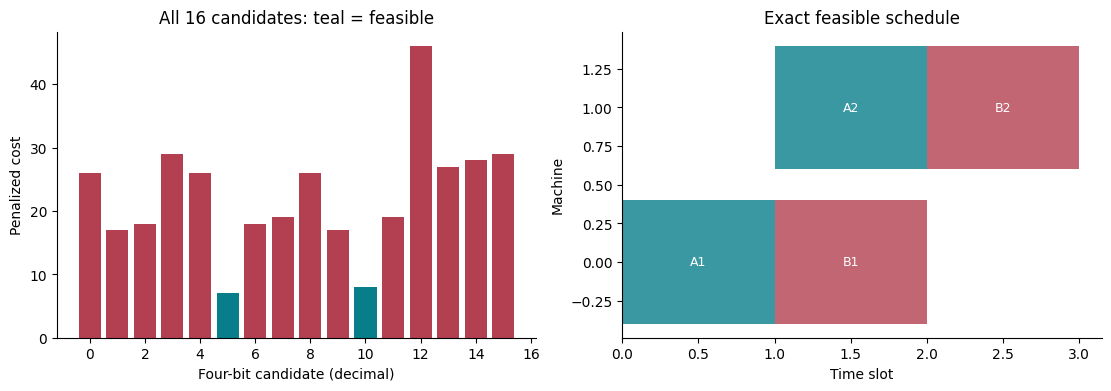

In [4]:
intermediate_tables(case)
plot_intermediate(case)

## 6. 实际运行与最终效果

模拟器使用固定种子逐次采样，counts 总数必须等于 shots。估计标准误由实际样本方差计算；近似 95% 区间可写作 estimate ± 1.96 × SE，但小样本及零计数需另用适当区间。本例不把这些区间当成硬件精度验收。

experiment,qubits,gates,shots,seed
qaoa,4,26,1024,20261023


observable,estimate,standard_error,ideal_reference
qaoa,14.422852,0.21883051,14.132704


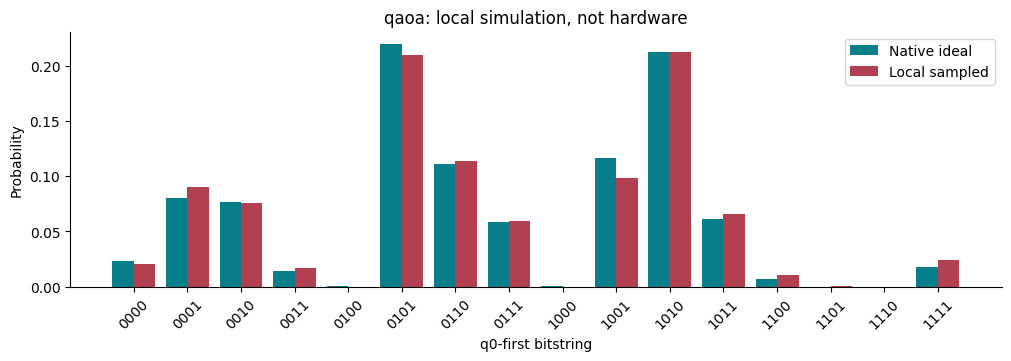

experiment,counts
qaoa,"{""0101"": 215, ""1001"": 101, ""1011"": 67, ""0010"": 78, ""1010"": 218, ""0011"": 17, ""0111"": 61, ""0110"": 117, ""1111"": 25, ""0001"": 92, ""1100"": 11, ""0000"": 21, ""1101"": 1}"


In [5]:
evidence = run_local_case(case, shots=SHOTS, seed=SEED)
show_measurements(case, evidence)

## 7. 可检查的电路输出

导出全部业务电路的 OpenQASM 2，位串采用 q0-first。可导出不等于已通过夸父设备门集、耦合图、深度和精度验收；本批不会访问凭据、提交任务或消耗金融额度。纯经典案例没有伪造量子电路。

In [6]:
for name, result in evidence['experiments'].items():
    print('\n---', name, '---\n'+result['openqasm2'])
if not evidence['experiments']:
    print('Classical cryptography / security workflow: no quantum circuit.')


--- qaoa ---
OPENQASM 2.0;
include "qelib1.inc";
qreg q[4];
creg c[4];
h q[0];
h q[1];
h q[2];
h q[3];
cx q[0],q[1];
rz(0.90169042399738275) q[1];
cx q[0],q[1];
cx q[0],q[2];
rz(-0.45084521199869149) q[2];
cx q[0],q[2];
rz(-0.4508452119986916) q[0];
cx q[1],q[3];
rz(-0.45084521199869149) q[3];
cx q[1],q[3];
rz(-0.4508452119986916) q[1];
cx q[2],q[3];
rz(0.90169042399738275) q[3];
cx q[2],q[3];
rz(0.27050712719921477) q[2];
rz(0.3606761695989531) q[3];
rz(2.7952403143918865) q[0];
u1(-2.7952403143918865) q[0];
rx(5.5165414137673423) q[0];
rx(5.5165414137673423) q[1];
rx(5.5165414137673423) q[2];
rx(5.5165414137673423) q[3];
measure q[0] -> c[0];
measure q[1] -> c[1];
measure q[2] -> c[2];
measure q[3] -> c[3];



## 8. 结果解释、复做与非目标

objective 是加权完工时间，makespan 另列。采样最优与精确最优分别呈现，不能用最频繁串替代可行性检查。

这是四工序固定路线作业车间案例；没有实现 TSP、车辆路径、复杂时间窗、设备故障或完整生产调度系统。

练习：对已有电路将 shots 改为 2048，比较估计与标准误；如果是纯经典密码案例，比较密文/公钥大小和篡改检测结果。安全案例的私钥只在临时目录或内存中存在，不输出密钥。重新执行此 Notebook 仍然只运行本地代码。

In [7]:
repeat = run_local_case(case, shots=2048, seed=SEED+100)
show_json({'execution_mode':repeat['execution_mode'], 'estimates':repeat['estimates'], 'new_cloud_tasks':repeat['new_cloud_tasks']})
assert all(sum(row['counts'].values()) == 2048 for row in repeat['experiments'].values())
assert repeat['new_cloud_tasks'] == 0
assert repeat['hardware_access'] is False

In [8]:
artifact = {'inputs':case.inputs, 'intermediate':case.intermediate, 'reference':case.reference, 'evidence':evidence}
path = root/'output/jupyter-notebook/industry/01_routing-scheduling_evidence.json'
path.parent.mkdir(parents=True, exist_ok=True)
path.write_text(json.dumps(artifact, ensure_ascii=False, indent=2), encoding='utf-8')
print('Evidence:', path.name)

Evidence: 01_routing-scheduling_evidence.json


## 9. 参考与责任边界

独立编写应用代码，未复制上游 SDK 实现或第三方教程代码；下列资料用于数学与接口背景。

- [Google OR-Tools 作业车间约束定义](https://developers.google.com/optimization/scheduling/job_shop)

本案例不是生产支持证书，也不代表 Qiskit / PennyLane 全量替代已经完成。